# Transfer de informație între active în meta-labeling (date de 4 ore)

**Întrebarea.** Rulăm *aceeași* strategie primară din `quant_forge.strategies`, cu *aceiași* parametri, pe cinci active
(BTC, ETH, BNB, SOL, XRP, spot Binance, bare de timp de 4h, 2021-09 → 2026-09). Pentru fiecare tranzacție un meta-model
estimează probabilitatea ca tranzacția să fie profitabilă net de costuri (`trade_return > 0`, ca în
`../test_primary_strategies_quantforge.ipynb`). Ne întrebăm dacă un meta-model antrenat pe tranzacțiile **tuturor activelor**
este mai bun, pe un activ dat, decât unul antrenat **doar pe tranzacțiile acelui activ**. Dacă da, informația din
caracteristici (features) se transmite între active.

**Regimuri de antrenare** (același set de test, aceleași caracteristici, același model; diferă doar datele de antrenare):

| Regim | Date de antrenare pentru activul țintă A |
|---|---|
| `OWN` | doar tranzacțiile lui A |
| `POOLED` | tranzacțiile tuturor celor 5 active (inclusiv A) |
| `POOLED_ID` | ca `POOLED`, plus indicatori one-hot ai activului (permite rate de bază diferite) |
| `OTHERS` | doar celelalte 4 active (transfer pur: modelul nu a văzut niciodată A) |
| `PRIOR_OWN` / `PRIOR_POOLED` | fără caracteristici: probabilitatea constantă = rata de câștig din antrenare |

**Metodologie** (ca în notebook-ul de referință): aceleași modele (regresie logistică L2 cu imputare mediană + standardizare,
și CatBoost cu `depth=2, iterations=150, learning_rate=0.03, l2_leaf_reg=10`), split cronologic, iar tranzacțiile de
antrenare trebuie să se fi **închis** înainte de începutul testului (purjare). Diferența față de referință: tăietura este o
**dată calendaristică comună tuturor activelor** (nu 70 % din tranzacțiile fiecărui activ), altfel modelul `POOLED` ar putea
învăța din tranzacții BTC simultane cu tranzacțiile ETH de test. Partea 1 reproduce split-ul unic din referință
(test = ultimele 18 luni); partea 2 repetă totul în *walk-forward* (ferestre de 6 luni), ca să avem mai multe predicții
out-of-sample și intervale de încredere.

**Ce înseamnă „mai bun”.** Măsura principală este log loss-ul out-of-sample (calitatea probabilității), comparat cu
`OWN` și cu rata de bază (`PRIOR_*`). AUC și PnL-ul tranzacțiilor acceptate sunt raportate separat. Un model care nu bate
rata de bază nu conține informație utilă, oricât de bun ar părea AUC-ul pe un eșantion mic.

## Configurare și date

In [73]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")


ROOT = find_project_root()
try:
    import quant_forge.strategies as qs
except ImportError:                      # library not pip-installed in this environment
    sys.path.insert(0, str(ROOT))
    import quant_forge.strategies as qs

DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"
# DATASETS = {
#     "BTC": "BTCUSDT_spot_time_4h_4h_20210901-20260901_e751456d",
#     "ETH": "ETHUSDT_spot_time_4h_4h_20210901-20260901_b90d1cad",
#     "BNB": "BNBUSDT_spot_time_4h_4h_20210901-20260901_1f29430e",
#     "SOL": "SOLUSDT_spot_time_4h_4h_20210901-20260901_cf904f73",
#     "XRP": "XRPUSDT_spot_time_4h_4h_20210901-20260901_62ae2e66",
#     "ADA": "ADAUSDT_spot_time_4h_4h_20210901-20260901_701a9690",
#     "AVA": "AVAXUSDT_spot_time_4h_4h_20210901-20260901_2bebb45e",
#     "BCH": "BCHUSDT_spot_time_4h_4h_20210901-20260901_c97b2f3c",
#     "DOGE": "DOGEUSDT_spot_time_4h_4h_20210901-20260901_ad02f3f7",
#     "DOT": "DOTUSDT_spot_time_4h_4h_20210901-20260901_5d118794",
#     "LINK": "LINKUSDT_spot_time_4h_4h_20210901-20260901_927c5683",
#     "LTC": "LTCUSDT_spot_time_4h_4h_20210901-20260901_835465c3",
#     "UNI": "UNIUSDT_spot_time_4h_4h_20210901-20260901_d94d67a9",
# }
DATASETS = {
    "BTC": "BTCUSDT_spot_time_4h_4h_20210901-20260901_e751456d",
    "ETH": "ETHUSDT_spot_time_4h_4h_20210901-20260901_b90d1cad",
    "BNB": "BNBUSDT_spot_time_4h_4h_20210901-20260901_1f29430e",
    "SOL": "SOLUSDT_spot_time_4h_4h_20210901-20260901_cf904f73",
    "XRP": "XRPUSDT_spot_time_4h_4h_20210901-20260901_62ae2e66",
    "ADA": "ADAUSDT_spot_time_4h_4h_20210901-20260901_701a9690",
    "AVAX": "AVAXUSDT_spot_time_4h_4h_20210901-20260901_2bebb45e",
    "BCH": "BCHUSDT_spot_time_4h_4h_20210901-20260901_c97b2f3c",
    "DOGE": "DOGEUSDT_spot_time_4h_4h_20210901-20260901_ad02f3f7",
    "DOT": "DOTUSDT_spot_time_4h_4h_20210901-20260901_5d118794",
    "LINK": "LINKUSDT_spot_time_4h_4h_20210901-20260901_927c5683",
    "LTC": "LTCUSDT_spot_time_4h_4h_20210901-20260901_835465c3",
    "UNI": "UNIUSDT_spot_time_4h_4h_20210901-20260901_d94d67a9",
    "AAVE": "AAVEUSDT_spot_time_4h_4h_20210901-20260901_d18c6b72",
    "ATOM": "ATOMUSDT_spot_time_4h_4h_20210901-20260901_f6d9acda",
    "ETC": "ETCUSDT_spot_time_4h_4h_20210901-20260901_252870d9",
    "FIL": "FILUSDT_spot_time_4h_4h_20210901-20260901_3acad466",
    "NEAR": "NEARUSDT_spot_time_4h_4h_20210901-20260901_7f93e453",
    "TRX": "TRXUSDT_spot_time_4h_4h_20210901-20260901_67a512ea",
    "XLM": "XLMUSDT_spot_time_4h_4h_20210901-20260901_f914dee7",
}
ASSETS = list(DATASETS)

FEE_BPS = 5.0          # per fill, all strategies (reference notebook: fee_bps=5)
SLIPPAGE_TICKS = 0     # uniform; tick size comes from each dataset manifest
FIXED_NOTIONAL = 10_000.0
TEST_START = pd.Timestamp("2025-03-01", tz="UTC")        # part 1: single split (~70 % of the calendar span)
WF_STARTS = pd.to_datetime(["2023-09-01", "2024-03-01", "2024-09-01", "2025-03-01", "2025-09-01", "2026-03-01"], utc=True)
WF_END = pd.Timestamp("2026-09-02", tz="UTC")
MIN_TRAIN = 20         # fewer training trades (or a single class) -> no model, the prediction falls back to the training prior
N_BOOT = 2000
SEED = 42

STRATEGIES = [
    qs.Strategies.RSI_CROSS_ABOVE,
    qs.Strategies.DONCHIAN_BREAKOUT_CONTINUATION,
    qs.Strategies.TIS_BTC_MOMENTUM_CONFLUENCE,
    qs.Strategies.SUPERTREND_REGIME_CONFLUENCE,
]
SHORT = {
    qs.Strategies.RSI_CROSS_ABOVE: "RSI",
    qs.Strategies.DONCHIAN_BREAKOUT_CONTINUATION: "DONCHIAN",
    qs.Strategies.TIS_BTC_MOMENTUM_CONFLUENCE: "TIS",
    qs.Strategies.SUPERTREND_REGIME_CONFLUENCE: "SUPERTREND",
}
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [74]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")


bars, ticks = {}, {}
for asset, name in DATASETS.items():
    manifest = json.loads((DATASETS_DIR / name / "manifest.json").read_text())
    df = set_datetime_index(pd.read_parquet(DATASETS_DIR / name / "time.parquet"))
    bars[asset] = df[~df.index.duplicated(keep="first")]
    ticks[asset] = 10.0 ** -int(manifest["instrument"]["price_decimals"])

pd.DataFrame({
    "bare": {a: len(d) for a, d in bars.items()},
    "prima bară": {a: d.index.min() for a, d in bars.items()},
    "ultima bară": {a: d.index.max() for a, d in bars.items()},
    "segmente": {a: d["segment_id"].nunique() for a, d in bars.items()},
    "bare complete (%)": {a: 100 * d["complete"].mean() for a, d in bars.items()},
    "tick": ticks,
})

,bare,prima bară,ultima bară,segmente,bare complete (%),tick
BTC,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-02
ETH,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-02
BNB,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-04
SOL,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-04
XRP,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-05
ADA,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-05
AVAX,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-04
BCH,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-02
DOGE,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-07
DOT,10956,2021-09-01 04:00:00+00:00,2026-09-01 00:00:00+00:00,1,100.0,1.000000e-04


## Caracteristici (features)

Pentru ca un model antrenat pe mai multe active să aibă sens, fiecare caracteristică trebuie să fie **adimensională**
(fără niveluri de preț sau volume în unitățile activului): distanțe în ATR, randamente relative, rapoarte, statistici t,
logaritmi relativi la propriul trecut. Nivelurile de preț ale strategiilor (`dc_high`, `st_band`, `atr_value`, …) nu sunt
folosite direct, ci doar ca rapoarte.

Fiecare strategie primește:

1. **caracteristici specifice strategiei** (geometria semnalului: RSI pentru RSI, canal/ADX pentru Donchian, serii de
   lumânări verzi pentru TIS, scorul și regimul pentru SuperTrend);
2. **context de volatilitate/trend**, comun;
3. **microstructură**, comună: dezechilibrul agresorilor (notional și tick rule), persistența fluxului pe ultima zi,
   statisticile t ale lambda Kyle/Hasbrouck (adimensionale, spre deosebire de lambda însuși), intensitatea și mărimea medie a
   tranzacțiilor relativ la ultimele 20 de bare, funding și premium index de pe perpetual.

Datele de order book (spread, adâncime) **nu există** în aceste build-uri de 4h (coloane goale), deci nu sunt folosite.

Toate caracteristicile se calculează din barele de până la bara semnalului inclusiv (`decision_time = bar_end`); biblioteca
copiază coloanele de context **doar de pe bara semnalului**. Pentru SuperTrend (care ia și short-uri) caracteristicile
direcționale sunt înmulțite cu `side`, ca „flux în direcția tranzacției” să însemne același lucru pentru long și short; la
strategiile long-only înmulțirea nu schimbă nimic.

In [75]:
def wilder(s, n):
    # Wilder RMA seeded with the SMA of the first n finite values (single segment, no interior gaps).
    a = s.to_numpy(dtype=float)
    out = np.full(len(a), np.nan)
    finite = np.flatnonzero(np.isfinite(a))
    if len(finite) and len(a) >= finite[0] + n:
        k = finite[0] + n - 1
        out[k] = a[finite[0]:k + 1].mean()
        for j in range(k + 1, len(a)):
            out[j] = out[j - 1] + (a[j] - out[j - 1]) / n
    return pd.Series(out, index=s.index)


def rsi(c, n):
    ch = c.diff()
    gain, loss = wilder(ch.clip(lower=0), n), wilder((-ch).clip(lower=0), n)
    return (100 * gain / (gain + loss)).mask((gain == 0) & (loss == 0), 50.0)


def div(a, b):
    return a / b.where(b != 0)


def segment_features(g):
    o, h, l, c = (g[k].astype(float) for k in ("open", "high", "low", "close"))
    f = pd.DataFrame(index=g.index)
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    tr.iloc[0] = h.iloc[0] - l.iloc[0]
    atr = wilder(tr, 14)
    r14 = rsi(c, 14)

    # strategy geometry
    f["fx_rsi_slope_3"] = r14.diff(3) / 300
    f["fx_rsi_prior_above_frac_20"] = (r14 > 70).astype(float).where(r14.notna()).shift(1).rolling(20).mean()
    f["fx_rsi_fast_slow_gap"] = (rsi(c, 7) - rsi(c, 28)) / 100
    ema50 = c.ewm(span=50, adjust=False, min_periods=50).mean()
    f["fx_ema50_distance_atr"] = div(c - ema50, atr)
    f["fx_directional_efficiency_20"] = div(c.diff(20), c.diff().abs().rolling(20).sum())
    f["fx_bb_width_rel_20"] = div(4 * c.rolling(20).std(ddof=0), c.rolling(20).mean())
    f["fx_runup_from_low_20_atr"] = div(c - l.shift(1).rolling(20).min(), atr)
    f["fx_candle_body_fraction"] = div(c - o, h - l)
    f["fx_dc_width_atr_30"] = div(h.shift(1).rolling(30).max() - l.shift(1).rolling(30).min(), atr)

    # volatility / trend context
    f["fx_rvol_ratio_1d_30d"] = np.log(div(g["rvol_1d"], g["rvol_30d"]))

    # microstructure (scale-free)
    f["fx_aggr_imbalance_mean_6"] = g["aggr_imbalance_notional"].rolling(6).mean()
    log_int = np.log(g["trade_intensity_per_s"].where(g["trade_intensity_per_s"] > 0))
    f["fx_trade_intensity_log_rel_20"] = log_int - log_int.shift(1).rolling(20).mean()
    log_size = np.log(div(g["notional_usdt"], g["n_trades"]))
    f["fx_avg_trade_notional_log_rel_20"] = log_size - log_size.shift(1).rolling(20).mean()
    return f


def add_features(df):
    return df.join(pd.concat([segment_features(g) for _, g in df.groupby("segment_id", sort=False)]).sort_index())


bars = {a: add_features(d) for a, d in bars.items()}

In [76]:
S = qs.Strategies
# columns copied from the signal bar (library `context_columns`) in addition to each strategy's own features
CONTEXT = ["fx_rvol_ratio_1d_30d", "trend_30d_volscaled"]
MICRO = [
    "aggr_imbalance_notional", "tick_imbalance_notional", "fx_aggr_imbalance_mean_6",
    "kyle_tstat_bars50_aggr", "hasbrouck_tstat_bars50_aggr",
    "fx_trade_intensity_log_rel_20", "fx_avg_trade_notional_log_rel_20",
    "funding_rate_last", "premium_index_binance_1m",
]
STRATEGY_SPECIFIC = {
    S.RSI_CROSS_ABOVE: ["rsi_value", "fx_rsi_slope_3", "fx_rsi_prior_above_frac_20", "fx_rsi_fast_slow_gap",
                        "fx_ema50_distance_atr", "fx_directional_efficiency_20", "fx_bb_width_rel_20"],
    S.DONCHIAN_BREAKOUT_CONTINUATION: ["adx_value", "di_diff", "long_breakout_atr", "ema_distance", "atr_rel",
                                       "fx_dc_width_atr_30", "fx_directional_efficiency_20"],
    S.TIS_BTC_MOMENTUM_CONFLUENCE: ["green_streak", "htf_green_streak", "tis_sma_distance_atr", "tis_atr_rel",
                                    "fx_candle_body_fraction", "fx_runup_from_low_20_atr", "fx_rsi_fast_slow_gap"],
    S.SUPERTREND_REGIME_CONFLUENCE: ["side", "st_regime", "st_atr_ratio", "st_adx", "st_adapt_multiplier", "signal_score",
                                     "st_ema_distance_atr", "st_sl_rel", "st_volume_log_rel", "fx_directional_efficiency_20"],
}
# direction-carrying features: multiplied by `side` (no-op for long-only strategies)
SIGNED = {"aggr_imbalance_notional", "tick_imbalance_notional", "fx_aggr_imbalance_mean_6", "funding_rate_last",
          "premium_index_binance_1m", "trend_30d_volscaled", "fx_rsi_fast_slow_gap", "fx_rsi_slope_3",
          "fx_ema50_distance_atr", "fx_directional_efficiency_20", "fx_candle_body_fraction"}
FEATURES = {s: STRATEGY_SPECIFIC[s] + CONTEXT + MICRO for s in STRATEGIES}
DERIVED = {"tis_sma_distance_atr", "tis_atr_rel", "st_ema_distance_atr", "st_sl_rel", "st_volume_log_rel", "side"}
{SHORT[s]: len(f) for s, f in FEATURES.items()}

{'RSI': 18, 'DONCHIAN': 18, 'TIS': 18, 'SUPERTREND': 21}

## Strategiile, așa cum le documentează biblioteca

Exemplu pentru SuperTrend (cea cu cele mai multe tranzacții și singura cu short-uri); celelalte au aceeași structură
(`qs.Strategies.<NUME>.spec.describe()`).

In [77]:
print(qs.Strategies.SUPERTREND_REGIME_CONFLUENCE.spec.describe()[:2500])

supertrend_regime_confluence - DefinedEdge SuperTrend Regime Confluence
SuperTrend flips with regime-adaptive multiplier, scored and filtered; stops/targets are anchored to the signal close; longs and shorts with reversals and a cooldown.
source: reference notebook primary_strategies.ipynb, strategy 'supertrend_regime_confluence' (Pine v6)
inputs:
  - open (required, ohlc): bar open
  - high (required, ohlc): bar high
  - low (required, ohlc): bar low
  - close (required, ohlc): bar close
  - bar_start_us (required, timestamp): bar start, integer microseconds since UTC epoch; strictly increasing
  - bar_end_us (required, timestamp): bar end, integer microseconds >= bar_start_us
  - first_trade_ts_us (optional, timestamp): first trade of the bar; fill time of next_open orders [absent -> bar_start_us]
  - bar_available_us (optional, timestamp): when the bar became available [absent -> bar_end_us]
  - decision_time_us (optional, timestamp): when decisions on the bar may be taken [absent -

## Rularea strategiilor pe toate activele

Parametri: valorile implicite ale fiecărei strategii, cu `fee_bps=5`, `slippage_ticks=0` și `tick_size` din manifestul
fiecărui activ (implicitul bibliotecii, 0.1, nu are sens pentru XRP). Pentru fiecare tranzacție închisă păstrăm
caracteristicile de la momentul deciziei, randamentul net și eticheta `y = 1[trade_return > 0]`.

In [78]:
frames, summaries = [], []
for strategy in STRATEGIES:
    context = [c for c in CONTEXT + MICRO + STRATEGY_SPECIFIC[strategy] if c.startswith("fx_") or c in bars["BTC"].columns]
    context = list(dict.fromkeys(context + ["close", "volume"]))
    for asset in ASSETS:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = qs.run_strategy(bars[asset], strategy, fee_bps=FEE_BPS, slippage_ticks=SLIPPAGE_TICKS,
                                  tick_size=ticks[asset], context_columns=context)
        t = res.closed_trades_frame().sort_values("decision_time").reset_index(drop=True)
        model_inputs = set(res.model_input_columns) | {"side"}
        # scale-free versions of the strategies' price-unit outputs
        if strategy is S.TIS_BTC_MOMENTUM_CONFLUENCE:
            t["tis_sma_distance_atr"] = (t["close"] - t["sma_trend"]) / t["atr_value"]
            t["tis_atr_rel"] = t["atr_value"] / t["close"]
        if strategy is S.SUPERTREND_REGIME_CONFLUENCE:
            t["st_ema_distance_atr"] = (t["close"] - t["st_ema"]) / t["atr_value"]
            t["st_sl_rel"] = t["sl_distance"] / t["close"]
            t["st_volume_log_rel"] = np.log(t["volume"] / t["st_vol_ma"])
        feats = FEATURES[strategy]
        assert set(feats) - DERIVED <= model_inputs, set(feats) - DERIVED - model_inputs
        assert not set(feats) & set(res.post_decision_columns)
        for c in SIGNED & set(feats):
            t[c] = t[c] * t["side"]
        t = t.assign(strategy=SHORT[strategy], asset=asset, y=t["trade_return"].gt(0).astype("int8"))
        frames.append(t[["strategy", "asset", "side", "decision_time", "entry_time", "exit_time", "trade_status",
                         "trade_return", "y"] + [c for c in feats if c != "side"]])
        summaries.append({"strategie": SHORT[strategy], "activ": asset, "tranzacții": len(t),
                          "win rate net (%)": 100 * t["y"].mean(),
                          "randament mediu net (bps)": 1e4 * t["trade_return"].mean(),
                          "PnL net (USD, 10k/tranz.)": FIXED_NOTIONAL * t["trade_return"].sum(),
                          "short (%)": 100 * t["side"].lt(0).mean()})

trades_all = pd.concat(frames, ignore_index=True)
for c in ["decision_time", "entry_time", "exit_time"]:
    trades_all[c] = pd.to_datetime(trades_all[c], utc=True)
summary = pd.DataFrame(summaries).set_index(["strategie", "activ"])
summary.round(2)

tranzacții  win rate net (%)  randament mediu net (bps)  PnL net (USD, 10k/tranz.)  short (%)
strategie  activ                                                                                               
RSI        BTC           176             32.95                      47.72                    8399.26       0.00
           ETH           177             35.59                      41.22                    7296.35       0.00
           BNB           169             26.63                       0.24                      40.76       0.00
           SOL           193             29.53                      27.89                    5382.64       0.00
           XRP           161             29.81                      29.76                    4791.92       0.00
...                      ...               ...                        ...                        ...        ...
SUPERTREND ETC           111             28.83                    -158.39                  -17580.91      45.05
           FIL           133             32.33                     -78.04                  -10379.08      46.62
           NEAR          128             34.38                      56.62                    7247.03      47.66
           TRX           119             41.18                      85.69                   10196.69      52.10
           XLM           104             50.00                     241.43                   25108.40      49.04

[80 rows x 5 columns]

Pe fiecare activ sunt doar 44–193 de tranzacții în cinci ani; pe Donchian și TIS ~50–70. Cu atât de puține exemple un
meta-model antrenat pe un singur activ este, aproape inevitabil, dominat de varianță. Asta e exact situația în care
agregarea mai multor active ar putea ajuta — *dacă* relația caracteristici → rezultat este aceeași pe toate activele.

### Cât de multă informație nouă aduc celelalte active?

Tranzacțiile aceleiași strategii pe active diferite au loc adesea **simultan** (criptomonedele se mișcă împreună), iar
atunci rezultatele lor sunt corelate. Două tranzacții simultane cu același rezultat nu aduc de două ori mai multă
informație. Tabelul arată, pentru fiecare strategie, ce fracție din tranzacții se suprapune în timp cu o tranzacție a
aceleiași strategii pe alt activ, cât de des perechile suprapuse au aceeași etichetă, cât ar fi acest procent dacă
etichetele ar fi independente (din ratele de câștig ale celor două membre ale perechilor) și corelația phi a etichetelor
(0 = independente).

In [79]:
rows = []
for s, g in trades_all.groupby("strategy", sort=False):
    st, en = g["decision_time"].to_numpy(), g["exit_time"].to_numpy()
    a, y = g["asset"].to_numpy(), g["y"].to_numpy()
    ov = (st[:, None] <= en[None, :]) & (st[None, :] <= en[:, None]) & (a[:, None] != a[None, :])
    i, j = np.nonzero(np.triu(ov, 1))
    pi, pj = y[i].mean(), y[j].mean()
    rows.append({"strategie": s, "tranzacții": len(g),
                 "cu suprapunere pe alt activ (%)": 100 * ov.any(axis=1).mean(),
                 "perechi suprapuse": len(i),
                 "aceeași etichetă (%)": 100 * (y[i] == y[j]).mean(),
                 "dacă ar fi independente (%)": 100 * (pi * pj + (1 - pi) * (1 - pj)),
                 "corelație phi a etichetelor": np.corrcoef(y[i], y[j])[0, 1]})
pd.DataFrame(rows).set_index("strategie").round(2)

,tranzacții,cu suprapunere pe alt activ (%),perechi suprapuse,aceeași etichetă (%),dacă ar fi independente (%),corelație phi a etichetelor
strategie,,,,,,
RSI,3237,89.31,12820,50.62,50.11,0.01
DONCHIAN,1177,96.01,5531,61.58,51.90,0.20
TIS,976,96.72,4794,63.93,50.39,0.27
SUPERTREND,2490,99.92,41856,51.61,50.13,0.03


## Modele și procedura de evaluare

Modelele sunt cele din notebook-ul de referință. Pentru `POOLED_ID` adăugăm coloane one-hot ale activului. Procedura de
antrenare/test este o singură funcție, folosită atât pentru split-ul unic (partea 1), cât și pentru walk-forward
(partea 2):

* pentru o fereastră de test `[w0, w1)`: test = tranzacțiile decise în fereastră; antrenare = tranzacțiile **închise**
  înainte de `w0` (pe toate activele, deci nicio tranzacție de antrenare nu se suprapune cu testul, indiferent de activ);
* fiecare regim produce o probabilitate pentru fiecare tranzacție de test; dacă un regim are mai puțin de `MIN_TRAIN`
  tranzacții de antrenare (sau o singură clasă), predicția devine rata de bază din antrenare și e marcată `fitted=False`.

In [80]:
from catboost import CatBoostClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def make_model(name):
    if name == "LogReg":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(penalty="l2", C=1.0, max_iter=1000))
    return CatBoostClassifier(iterations=150, depth=2, learning_rate=0.03, l2_leaf_reg=10, loss_function="Logloss",
                              random_seed=SEED, verbose=False, allow_writing_files=False, thread_count=4)


MODELS = ["LogReg", "CatBoost"]
REGIMES = ["OWN", "POOLED", "POOLED_ID", "OTHERS"]
ASSET_DUMMIES = [f"asset_{a}" for a in ASSETS]


def design(frame, feats, with_id):
    X = frame[feats].astype(float)
    if with_id:
        X = X.join(pd.DataFrame({f"asset_{a}": frame["asset"].eq(a).astype(float) for a in ASSETS}, index=frame.index))
    return X


def fit_predict(model_name, train, test, feats, with_id=False):
    # returns (probabilities, fitted flag)
    prior = train["y"].mean() if len(train) else 0.5
    if len(train) < MIN_TRAIN or train["y"].nunique() < 2:
        return np.full(len(test), prior), False
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = make_model(model_name).fit(design(train, feats, with_id), train["y"])
        p = m.predict_proba(design(test, feats, with_id))[:, list(m.classes_).index(1)]
    return p, True


def predict_window(trades, feats, w0, w1):
    train_all = trades.loc[trades["exit_time"] < w0]
    test_all = trades.loc[(trades["decision_time"] >= w0) & (trades["decision_time"] < w1)]
    out = []
    if test_all.empty:
        return out
    for model_name in MODELS:
        pooled, fit_pooled = fit_predict(model_name, train_all, test_all, feats)
        pooled_id, fit_pooled_id = fit_predict(model_name, train_all, test_all, feats, with_id=True)
        pooled = pd.Series(pooled, index=test_all.index)
        pooled_id = pd.Series(pooled_id, index=test_all.index)
        for asset, test in test_all.groupby("asset"):
            own_train = train_all.loc[train_all["asset"].eq(asset)]
            oth_train = train_all.loc[train_all["asset"].ne(asset)]
            own, fit_own = fit_predict(model_name, own_train, test, feats)
            oth, fit_oth = fit_predict(model_name, oth_train, test, feats)
            for regime, p, fitted, n_train in [("OWN", own, fit_own, len(own_train)),
                                               ("POOLED", pooled.loc[test.index], fit_pooled, len(train_all)),
                                               ("POOLED_ID", pooled_id.loc[test.index], fit_pooled_id, len(train_all)),
                                               ("OTHERS", oth, fit_oth, len(oth_train))]:
                out.append(pd.DataFrame({"row": test.index, "model": model_name, "regime": regime, "p": np.asarray(p),
                                         "fitted": fitted, "n_train": n_train, "window": w0}))
            if model_name == MODELS[0]:      # constant baselines, once per window
                for regime, tr in [("PRIOR_OWN", own_train), ("PRIOR_POOLED", train_all)]:
                    out.append(pd.DataFrame({"row": test.index, "model": "prior", "regime": regime,
                                             "p": tr["y"].mean() if len(tr) else 0.5, "fitted": True,
                                             "n_train": len(tr), "window": w0}))
    return out


def run_windows(windows):
    parts = []
    for s in trades_all["strategy"].unique():
        trades = trades_all.loc[trades_all["strategy"].eq(s)]
        feats = [c for c in FEATURES[[k for k, v in SHORT.items() if v == s][0]]]
        for w0, w1 in windows:
            parts += predict_window(trades, feats, w0, w1)
    pred = pd.concat(parts, ignore_index=True)
    pred = pred.join(trades_all[["strategy", "asset", "decision_time", "trade_return", "y"]], on="row")
    # the training prior of the same asset/window (for an acceptance threshold that is not fitted on test data)
    prior_own = pred.loc[pred["regime"].eq("PRIOR_OWN"), ["row", "window", "p"]].rename(columns={"p": "prior_own"})
    return pred.merge(prior_own, on=["row", "window"], how="left")

In [81]:
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 and np.ptp(p) > 0 else np.nan


def metrics(g):
    p = np.clip(g["p"].to_numpy(float), 1e-6, 1 - 1e-6)
    y, r = g["y"].to_numpy(), g["trade_return"].to_numpy()
    acc50, accp = p >= 0.5, p >= g["prior_own"].to_numpy()
    pnl_all = FIXED_NOTIONAL * r.sum()
    return pd.Series({
        "n": len(g), "fitted (%)": 100 * g["fitted"].mean(),
        "log_loss": log_loss(y, p, labels=[0, 1]), "auc": safe_auc(y, p), "brier": np.mean((p - y) ** 2),
        "acc@0.5 (%)": 100 * acc50.mean(), "pnl@0.5": FIXED_NOTIONAL * r[acc50].sum(),
        "lift@0.5": FIXED_NOTIONAL * r[acc50].sum() - acc50.mean() * pnl_all,
        "acc@prior (%)": 100 * accp.mean(), "pnl@prior": FIXED_NOTIONAL * r[accp].sum(),
        "lift@prior": FIXED_NOTIONAL * r[accp].sum() - accp.mean() * pnl_all,
        "pnl_all": pnl_all,
    })


def metric_table(pred, by=("strategy", "asset", "model", "regime")):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return pred.groupby(list(by), sort=False).apply(metrics)


def paired_delta(pred, regime, ref, model, by_strategy=True):
    # per-trade log-loss difference regime - ref (negative = regime better), month-block bootstrap CI
    a = pred.loc[pred["regime"].eq(regime) & pred["model"].eq(model)].set_index(["row", "window"])
    refm = "prior" if ref.startswith("PRIOR") else model
    b = pred.loc[pred["regime"].eq(ref) & pred["model"].eq(refm)].set_index(["row", "window"])
    j = a.join(b[["p"]], rsuffix="_ref", how="inner")
    ll = lambda p, y: -(y * np.log(np.clip(p, 1e-6, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-6, 1)))
    j["d"] = ll(j["p"], j["y"]) - ll(j["p_ref"], j["y"])
    j["month"] = j["decision_time"].dt.strftime("%Y-%m")
    rng = np.random.default_rng(SEED)
    rows = []
    groups = j.groupby("strategy", sort=False) if by_strategy else [("TOATE", j)]
    for s, g in groups:
        m = g.groupby("month")["d"].agg(["sum", "count"])
        idx = rng.integers(0, len(m), size=(N_BOOT, len(m)))
        boot = m["sum"].to_numpy()[idx].sum(1) / m["count"].to_numpy()[idx].sum(1)
        rows.append({"strategie": s, "regim": regime, "vs": ref, "model": model, "n": len(g),
                     "Δ log loss mediu": g["d"].mean(), "IC 95% jos": np.quantile(boot, 0.025),
                     "IC 95% sus": np.quantile(boot, 0.975), "P(Δ<0) bootstrap": (boot < 0).mean(),
                     "active cu Δ<0": int((g.groupby("asset")["d"].mean() < 0).sum())})
    return pd.DataFrame(rows)

## Partea 1 — split unic, ca în notebook-ul de referință

Antrenare: tranzacțiile închise înainte de 2025-03-01. Test: tranzacțiile decise de la 2025-03-01 până la sfârșitul
datelor (2026-09-01). Setul de test este identic pentru toate regimurile.

In [82]:
pred1 = run_windows([(TEST_START, WF_END)])
m1 = metric_table(pred1)
n_split = (trades_all.assign(set=np.where(trades_all["decision_time"] >= TEST_START, "test",
                                          np.where(trades_all["exit_time"] < TEST_START, "train", "purged")))
           .groupby(["strategy", "asset", "set"]).size().unstack(fill_value=0))
n_split

set             purged  test  train
strategy asset                     
DONCHIAN AAVE        0    19     47
         ADA         0    18     41
         ATOM        0    16     40
         AVAX        0    14     48
         BCH         0    15     38
...                ...   ...    ...
TIS      SOL         0    13     39
         TRX         0    17     44
         UNI         0    12     35
         XLM         0    13     37
         XRP         0    13     35

[80 rows x 3 columns]

### Un exemplu în detaliu (ETH, SuperTrend, CatBoost)

Aceleași rapoarte ca în notebook-ul de referință, pentru `OWN` și `POOLED`.

In [83]:
EX_S, EX_A, EX_M = "SUPERTREND", "ETH", "CatBoost"
ex = pred1.loc[pred1["strategy"].eq(EX_S) & pred1["asset"].eq(EX_A)]
for regime in ["OWN", "POOLED"]:
    e = ex.loc[ex["regime"].eq(regime) & ex["model"].eq(EX_M)]
    print(f"=== {regime}: ROC-AUC {safe_auc(e['y'], e['p']):.4f} | Neg Log Loss {-log_loss(e['y'], e['p'], labels=[0, 1]):.4f}")
    print(classification_report(e["y"], (e["p"] >= 0.5).astype(int), labels=[0, 1],
                                target_names=["Fără profit net", "Profit net pozitiv"], digits=3, zero_division=0))

=== OWN: ROC-AUC 0.5014 | Neg Log Loss -0.7168
                    precision    recall  f1-score   support

   Fără profit net      0.556     0.714     0.625        21
Profit net pozitiv      0.455     0.294     0.357        17

          accuracy                          0.526        38
         macro avg      0.505     0.504     0.491        38
      weighted avg      0.510     0.526     0.505        38

=== POOLED: ROC-AUC 0.6134 | Neg Log Loss -0.6710
                    precision    recall  f1-score   support

   Fără profit net      0.583     1.000     0.737        21
Profit net pozitiv      1.000     0.118     0.211        17

          accuracy                          0.605        38
         macro avg      0.792     0.559     0.474        38
      weighted avg      0.770     0.605     0.501        38



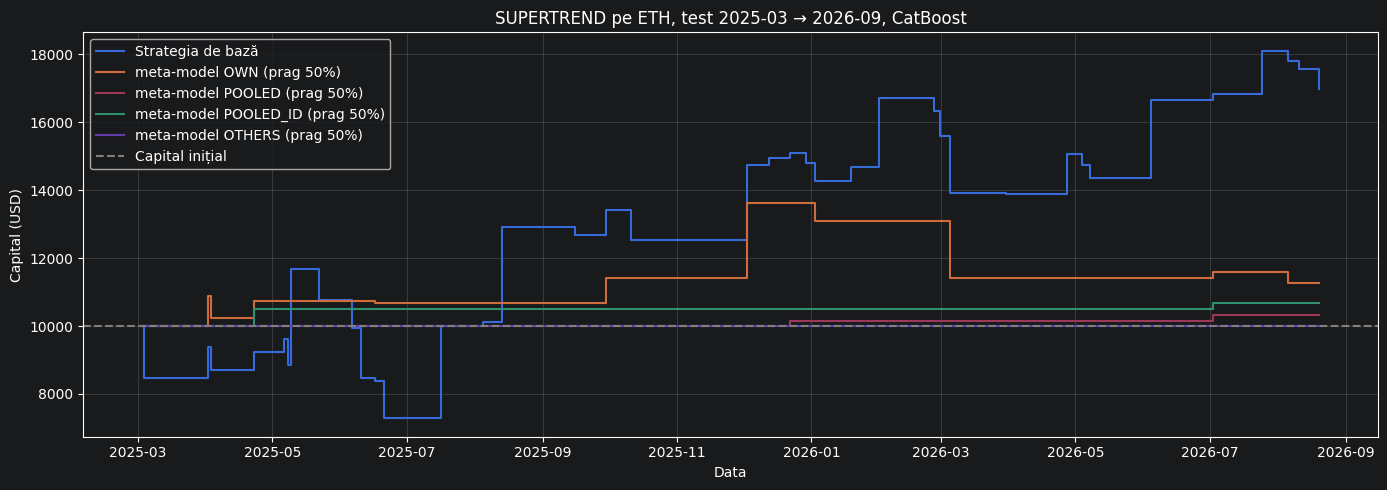

,Capital final (USD),PnL net (USD),Tranzacții,Semnale păstrate (%),Win rate net (%),Randament mediu net (%)
Variantă,,,,,,
Strategia de bază,16968.159366,6968.159366,38,100.000000,44.736842,1.833726
meta-model OWN (prag 50%),11276.694019,1276.694019,11,28.947368,45.454545,1.160631
meta-model POOLED (prag 50%),10332.293143,332.293143,2,5.263158,100.000000,1.661466
meta-model POOLED_ID (prag 50%),10683.744472,683.744472,2,5.263158,100.000000,3.418722
meta-model OTHERS (prag 50%),10000.000000,0.000000,0,0.000000,NaN,NaN


In [84]:
def plot_selection_equity(test_trades, probs, threshold=0.50, initial_capital=10_000, position_size=10_000, title=""):
    # reference plot_strategy_equity, but taking one probability vector per variant
    t = test_trades.loc[test_trades["trade_status"].eq("closed")].copy()
    order = t["exit_time"].sort_values(kind="stable").index
    t = t.loc[order]
    net_return = t["trade_return"]
    pnl = net_return * position_size
    dates = [t["entry_time"].min(), *t["exit_time"].tolist()]
    selections = {"Strategia de bază": pd.Series(True, index=t.index)}
    for name, p in probs.items():
        selections[f"{name} (prag {threshold:.0%})"] = p.loc[t.index].ge(threshold)
    fig, ax = plt.subplots(figsize=(14, 5))
    summary = []
    for name, accepted in selections.items():
        selected_pnl = pnl.where(accepted, 0.0)
        equity = initial_capital + selected_pnl.cumsum()
        accepted_returns = net_return.loc[accepted]
        ax.step(dates, [initial_capital, *equity.tolist()], where="post", linewidth=1.5, label=name)
        summary.append({"Variantă": name, "Capital final (USD)": equity.iloc[-1], "PnL net (USD)": selected_pnl.sum(),
                        "Tranzacții": int(accepted.sum()), "Semnale păstrate (%)": 100 * accepted.mean(),
                        "Win rate net (%)": 100 * accepted_returns.gt(0).mean(),
                        "Randament mediu net (%)": 100 * accepted_returns.mean()})
    ax.axhline(initial_capital, color="gray", linestyle="--", label="Capital inițial")
    ax.set(title=title or "Curba capitalului la închiderea tranzacțiilor", xlabel="Data", ylabel="Capital (USD)")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(summary).set_index("Variantă")


ex_trades = trades_all.loc[ex["row"].unique()]
ex_probs = {f"meta-model {r}": ex.loc[ex["regime"].eq(r) & ex["model"].eq(EX_M)].set_index("row")["p"]
            for r in ["OWN", "POOLED", "POOLED_ID", "OTHERS"]}
plot_selection_equity(ex_trades, ex_probs, title=f"{EX_S} pe {EX_A}, test 2025-03 → 2026-09, {EX_M}")

### Toate activele și strategiile: log loss și AUC pe test

Fiecare celulă: valoarea pe setul de test al activului. `PRIOR_OWN` este referința minimă (rata de câștig din antrenare a
activului). În tabelul de log loss, o valoare mai mică decât `PRIOR_OWN` înseamnă că modelul conține informație; o valoare
mai mică la `POOLED` decât la `OWN` înseamnă că agregarea activelor ajută.

In [85]:
def wide(table, col, models=("LogReg", "CatBoost")):
    t = table[col].unstack("regime")
    base = t.xs("prior", level="model")[["PRIOR_OWN", "PRIOR_POOLED"]]
    blocks = {m: t.xs(m, level="model")[REGIMES] for m in models}
    return pd.concat({**blocks, "prior": base}, axis=1)


ll1 = wide(m1, "log_loss")
ll1.style.format("{:.3f}").background_gradient(axis=1, cmap="RdYlGn_r")

In [86]:
auc1 = wide(m1, "auc", )
auc1.drop(columns="prior", level=0).style.format("{:.3f}").background_gradient(axis=None, cmap="RdYlGn", vmin=0.3, vmax=0.7)

In [87]:
def regime_score(table, models=MODELS):
    rows = []
    for m in models:
        t = table.xs(m, level="model")
        own, prior = t.xs("OWN", level="regime"), table.xs("prior", level="model").xs("PRIOR_OWN", level="regime")
        for r in REGIMES:
            x = t.xs(r, level="regime")
            rows.append({"model": m, "regim": r,
                         "log loss mediu": x["log_loss"].mean(),
                         "celule < PRIOR_OWN": f'{int((x["log_loss"] < prior["log_loss"]).sum())}/{len(x)}',
                         "celule < OWN": f'{int((x["log_loss"] < own["log_loss"]).sum())}/{len(x)}' if r != "OWN" else "",
                         "AUC mediu": x["auc"].mean(),
                         "lift@0.5 total (USD)": x["lift@0.5"].sum(),
                         "lift@prior total (USD)": x["lift@prior"].sum()})
    x = table.xs("prior", level="model")
    for r in ["PRIOR_OWN", "PRIOR_POOLED"]:
        rows.append({"model": "prior", "regim": r, "log loss mediu": x.xs(r, level="regime")["log_loss"].mean()})
    return pd.DataFrame(rows).set_index(["model", "regim"])


regime_score(m1).round(4)

log loss mediu celule < PRIOR_OWN celule < OWN  AUC mediu  lift@0.5 total (USD)  lift@prior total (USD)
model    regim                                                                                                                
LogReg   OWN                   0.8481              13/80                  0.5598            27459.6349              57114.7302
         POOLED                0.6443              36/80        68/80     0.5668            35668.4794              37389.5702
         POOLED_ID             0.6562              36/80        64/80     0.5724            47204.5323              57480.1620
         OTHERS                0.6488              32/80        64/80     0.5639            47588.8181              36118.6006
CatBoost OWN                   0.6530              35/80                  0.5309            28530.3889              24878.2738
         POOLED                0.6346              48/80        52/80     0.5594            -5588.5349              25404.1203
         POOLED_ID             0.6347              44/80        52/80     0.5620             3804.0517              39341.6630
         OTHERS                0.6351              48/80        49/80     0.5583            -6199.4760              30388.2227
prior    PRIOR_OWN             0.6423                NaN          NaN        NaN                   NaN                     NaN
         PRIOR_POOLED          0.6362                NaN          NaN        NaN                   NaN                     NaN

`lift@…` = PnL-ul net al tranzacțiilor acceptate minus PnL-ul așteptat al unei selecții **aleatoare** cu aceeași rată de
acceptare (fracția acceptată × PnL-ul tuturor tranzacțiilor). Un filtru care doar reduce numărul de tranzacții are lift 0
în medie; doar un lift pozitiv arată selecție. `@0.5` = pragul din referință; `@prior` = acceptă dacă probabilitatea
depășește rata de câștig din antrenare a activului (prag fixat fără date de test, util când rata de bază e departe de 50 %,
ca la RSI).

## Partea 2 — walk-forward (ferestre de test de 6 luni, antrenare expansivă)

Split-ul unic are 10–60 de tranzacții de test pe celulă, deci diferențele dintre regimuri sunt dominate de zgomot. Aici
fiecare tranzacție decisă între 2023-09-01 și 2026-09-01 primește o predicție out-of-sample de la un model antrenat doar pe
tranzacțiile închise înaintea ferestrei sale. Diferențele de log loss se compară **pereche cu pereche** (aceeași
tranzacție, regimuri diferite), cu intervale de încredere din bootstrap pe blocuri lunare (tranzacțiile din aceeași lună și
de pe active diferite sunt corelate, deci nu pot fi tratate ca independente).

In [88]:
windows = list(zip(WF_STARTS, [*WF_STARTS[1:], WF_END]))
pred2 = run_windows(windows)
m2 = metric_table(pred2)
fit_rate = (pred2.loc[pred2["model"].ne("prior")].groupby(["strategy", "regime"])["fitted"].mean().unstack() * 100).round(1)
print("predicții făcute de un model antrenat (restul = fallback la rata de bază), %:")
fit_rate

predicții făcute de un model antrenat (restul = fallback la rata de bază), %:


regime,OTHERS,OWN,POOLED,POOLED_ID
strategy,,,,
DONCHIAN,100.0,90.7,100.0,100.0
RSI,100.0,100.0,100.0,100.0
SUPERTREND,100.0,100.0,100.0,100.0
TIS,100.0,81.3,100.0,100.0


In [89]:
ll2 = wide(m2, "log_loss")
ll2.style.format("{:.3f}").background_gradient(axis=1, cmap="RdYlGn_r")

In [90]:
regime_score(m2).round(4)

log loss mediu celule < PRIOR_OWN celule < OWN  AUC mediu  lift@0.5 total (USD)  lift@prior total (USD)
model    regim                                                                                                                
LogReg   OWN                   0.8978               1/80                  0.5152            -7075.9811              39702.0845
         POOLED                0.6656              37/80        79/80     0.5266           -21446.7797              51583.0987
         POOLED_ID             0.6824              23/80        79/80     0.5109             8314.6955              75101.2605
         OTHERS                0.6681              34/80        78/80     0.5247           -21447.2551              77025.4159
CatBoost OWN                   0.6800              21/80                  0.4683            17330.2218                225.1767
         POOLED                0.6546              49/80        65/80     0.5060           -52548.1477              16812.7298
         POOLED_ID             0.6564              49/80        62/80     0.5065           -52286.1458              41893.0064
         OTHERS                0.6549              49/80        65/80     0.5113           -61849.0092              34789.7870
prior    PRIOR_OWN             0.6645                NaN          NaN        NaN                   NaN                     NaN
         PRIOR_POOLED          0.6545                NaN          NaN        NaN                   NaN                     NaN

### Testul principal: diferențe pereche de log loss

`Δ log loss mediu` < 0 înseamnă că regimul din coloana `regim` dă probabilități mai bune decât cel din `vs` pe aceleași
tranzacții. Un interval de încredere care conține 0 înseamnă că diferența nu se distinge de zgomot.

In [91]:
tests = []
for model in MODELS:
    for regime, ref in [("POOLED", "OWN"), ("POOLED_ID", "OWN"), ("OTHERS", "OWN"),
                        ("OWN", "PRIOR_OWN"), ("POOLED", "PRIOR_OWN"), ("POOLED_ID", "PRIOR_POOLED"), ("POOLED", "PRIOR_POOLED")]:
        tests.append(paired_delta(pred2, regime, ref, model))
        tests.append(paired_delta(pred2, regime, ref, model, by_strategy=False))
tests = pd.concat(tests, ignore_index=True).set_index(["model", "regim", "vs", "strategie"]).sort_index()
tests.round(4)

n  Δ log loss mediu  IC 95% jos  IC 95% sus  P(Δ<0) bootstrap  active cu Δ<0
model    regim     vs           strategie                                                                                  
CatBoost OTHERS    OWN          DONCHIAN     782           -0.0102     -0.0270      0.0070            0.8865             14
                                RSI         2070           -0.0130     -0.0216     -0.0049            0.9990             18
                                SUPERTREND  1496           -0.0290     -0.0498     -0.0090            0.9985             15
                                TIS          621           -0.0465     -0.0682     -0.0232            1.0000             18
                                TOATE       4969           -0.0215     -0.0321     -0.0115            1.0000             19
...                                          ...               ...         ...         ...               ...            ...
LogReg   POOLED_ID PRIOR_POOLED DONCHIAN     782            0.0347      0.0067      0.0667            0.0070              5
                                RSI         2070            0.0168      0.0100      0.0232            0.0000              1
                                SUPERTREND  1496            0.0201     -0.0097      0.0508            0.0975              7
                                TIS          621            0.0339     -0.0224      0.0809            0.1120              6
                                TOATE       4969            0.0227      0.0098      0.0366            0.0005              3

[70 rows x 6 columns]

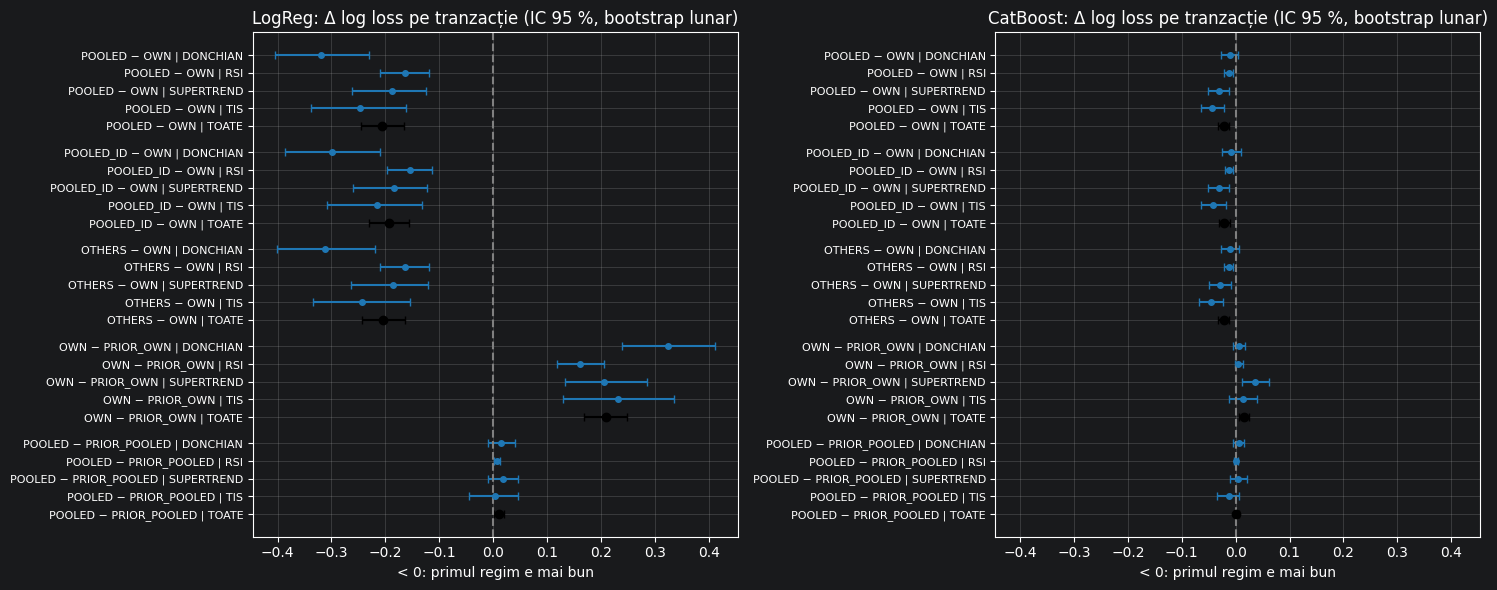

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
pairs = [("POOLED", "OWN"), ("POOLED_ID", "OWN"), ("OTHERS", "OWN"), ("OWN", "PRIOR_OWN"), ("POOLED", "PRIOR_POOLED")]
for ax, model in zip(axes, MODELS):
    t = tests.xs(model, level="model").reset_index()
    labels, ypos, y = [], [], 0.0
    for regime, ref in pairs:
        for _, r in t.loc[t["regim"].eq(regime) & t["vs"].eq(ref)].iterrows():
            bold = r["strategie"] == "TOATE"
            ax.errorbar(r["Δ log loss mediu"], y, xerr=[[r["Δ log loss mediu"] - r["IC 95% jos"]],
                        [r["IC 95% sus"] - r["Δ log loss mediu"]]], fmt="o", color="black" if bold else "tab:blue",
                        capsize=3, markersize=6 if bold else 4)
            labels.append(f"{regime} − {ref} | {r['strategie']}")
            ypos.append(y)
            y += 1
        y += 0.5
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(ypos)
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f"{model}: Δ log loss pe tranzacție (IC 95 %, bootstrap lunar)")
    ax.set_xlabel("< 0: primul regim e mai bun")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### PnL out-of-sample al filtrelor (walk-forward)

Suma pe toate activele, pentru fiecare strategie: PnL-ul tuturor tranzacțiilor (`pnl_all`), PnL-ul tranzacțiilor acceptate
și lift-ul față de selecția aleatoare cu aceeași rată de acceptare.

In [93]:
pnl2 = (m2.reset_index().groupby(["strategy", "model", "regime"], sort=False)
        [["n", "pnl_all", "acc@0.5 (%)", "pnl@0.5", "lift@0.5", "acc@prior (%)", "pnl@prior", "lift@prior"]]
        .agg({"n": "sum", "pnl_all": "sum", "acc@0.5 (%)": "mean", "pnl@0.5": "sum", "lift@0.5": "sum",
              "acc@prior (%)": "mean", "pnl@prior": "sum", "lift@prior": "sum"}))
pnl2.loc[pnl2.index.get_level_values("model") != "prior"].round(0)

n   pnl_all  acc@0.5 (%)   pnl@0.5  lift@0.5  acc@prior (%)  pnl@prior  lift@prior
strategy   model    regime                                                                                            
RSI        LogReg   OWN        2070.0   78350.0         18.0   12101.0   -1611.0           44.0    29589.0     -2784.0
                    POOLED     2070.0   78350.0          0.0    2734.0    2224.0           57.0    56202.0      6447.0
                    POOLED_ID  2070.0   78350.0          1.0    4182.0    2941.0           56.0    51283.0      6609.0
                    OTHERS     2070.0   78350.0          1.0    2776.0    2129.0           55.0    59622.0     11542.0
           CatBoost OWN        2070.0   78350.0          1.0    -706.0   -1920.0           69.0    57567.0       -58.0
                    POOLED     2070.0   78350.0          0.0       0.0       0.0           58.0    56368.0      6774.0
                    POOLED_ID  2070.0   78350.0          0.0       0.0       0.0           57.0    61303.0     13247.0
                    OTHERS     2070.0   78350.0          0.0       0.0       0.0           58.0    55092.0      6356.0
DONCHIAN   LogReg   OWN         782.0  132266.0         55.0   79158.0    4401.0           59.0    99168.0     19201.0
                    POOLED      782.0  132266.0         65.0   93452.0    1603.0           58.0    68933.0       289.0
                    POOLED_ID   782.0  132266.0         63.0   77667.0  -11792.0           64.0    86021.0      2174.0
                    OTHERS      782.0  132266.0         65.0  101244.0    9777.0           57.0    77851.0     10479.0
           CatBoost OWN         782.0  132266.0         58.0   45064.0  -40960.0           57.0    39468.0    -32368.0
                    POOLED      782.0  132266.0         63.0   35430.0  -49262.0           50.0    45612.0     -6693.0
                    POOLED_ID   782.0  132266.0         63.0   38781.0  -47076.0           54.0    49480.0     -7396.0
                    OTHERS      782.0  132266.0         64.0   34516.0  -48475.0           50.0    46170.0     -4208.0
TIS        LogReg   OWN         621.0  117531.0         29.0   50143.0   18220.0           56.0    83996.0     24617.0
                    POOLED      621.0  117531.0         12.0   22237.0    2401.0           53.0   119553.0     64506.0
                    POOLED_ID   621.0  117531.0         18.0   45133.0   18158.0           52.0   120894.0     63647.0
                    OTHERS      621.0  117531.0         14.0   15929.0   -2499.0           55.0   124587.0     71819.0
           CatBoost OWN         621.0  117531.0         12.0   43793.0   24697.0           83.0    86356.0     -3161.0
                    POOLED      621.0  117531.0          0.0       0.0       0.0           63.0    86165.0     30023.0
                    POOLED_ID   621.0  117531.0          0.0    2168.0    1677.0           57.0    79398.0     23536.0
                    OTHERS      621.0  117531.0          0.0     641.0     487.0           62.0    82725.0     30728.0
SUPERTREND LogReg   OWN        1496.0  117405.0         37.0   20021.0  -28086.0           51.0    60718.0     -1331.0
                    POOLED     1496.0  117405.0         21.0   -3274.0  -27675.0           55.0    24867.0    -19659.0
                    POOLED_ID  1496.0  117405.0         24.0   36397.0    -992.0           55.0    60891.0      2671.0
                    OTHERS     1496.0  117405.0         21.0   -5140.0  -30855.0           54.0    26952.0    -16816.0
           CatBoost OWN        1496.0  117405.0         28.0   79041.0   35513.0           50.0    96872.0     35812.0
                    POOLED     1496.0  117405.0          8.0    2380.0   -3286.0           53.0    30474.0    -13291.0
                    POOLED_ID  1496.0  117405.0          8.0    1273.0   -6887.0           54.0    58479.0     12505.0
                    OTHERS     1496.0  117405.0          7.0   -7328.0  -13861.0           52.0    43203.0   

### Este relația caracteristici → rezultat aceeași pe toate activele?

Dacă transferul eșuează, un motiv posibil este că aceeași caracteristică are efect diferit pe active diferite. Pentru
fiecare strategie și caracteristică calculăm corelația Spearman cu rezultatul (`trade_return`) **separat pe fiecare activ**,
pe tot eșantionul (diagnostic descriptiv, nu e folosit în modele). Semne care se schimbă de la un activ la altul și
magnitudini de ordinul zgomotului (|ρ| < 2/√n, cu n ≈ 50–190) înseamnă că nu există o relație comună de transferat.

In [94]:
from scipy.stats import spearmanr

rows = []
for s in trades_all["strategy"].unique():
    feats = [c for c in FEATURES[[k for k, v in SHORT.items() if v == s][0]] if c != "side"]
    g_s = trades_all.loc[trades_all["strategy"].eq(s)]
    for c in feats:
        rho = {}
        for a, g in g_s.groupby("asset"):
            ok = g[c].notna()
            rho[a] = spearmanr(g.loc[ok, c], g.loc[ok, "trade_return"]).statistic if ok.sum() > 10 and g.loc[ok, c].nunique() > 1 else np.nan
        r = pd.Series(rho)
        rows.append({"strategie": s, "caracteristică": c, **rho,
                     "semn comun": int(max((r > 0).sum(), (r < 0).sum())),
                     "ρ mediu": r.mean(), "zgomot ~2/√n": 2 / np.sqrt(len(g_s) / len(ASSETS))})
rho_tab = pd.DataFrame(rows).set_index(["strategie", "caracteristică"])
rho_tab.style.format("{:.2f}", subset=ASSETS + ["ρ mediu", "zgomot ~2/√n"]).background_gradient(
    subset=ASSETS, cmap="RdBu", vmin=-0.4, vmax=0.4)

In [95]:
consistency = rho_tab.groupby("strategie").agg(
    caracteristici=("ρ mediu", "size"),
    cu_semn_comun_pe_5_active=("semn comun", lambda x: int((x == 5).sum())),
    cu_semn_comun_pe_4_active=("semn comun", lambda x: int((x >= 4).sum())),
    abs_rho_mediu_max=("ρ mediu", lambda x: x.abs().max()),
)
# under independence each feature has the same sign on all 5 assets with probability 2 * 0.5**5 = 6.25 %
consistency["așteptat la întâmplare (5/5)"] = consistency["caracteristici"] * 2 * 0.5 ** 5
consistency["așteptat la întâmplare (≥4/5)"] = consistency["caracteristici"] * 2 * 6 * 0.5 ** 5
consistency.round(2)

,caracteristici,cu_semn_comun_pe_5_active,cu_semn_comun_pe_4_active,abs_rho_mediu_max,așteptat la întâmplare (5/5),așteptat la întâmplare (≥4/5)
strategie,,,,,,
DONCHIAN,18,0,18,0.07,1.12,6.75
RSI,18,0,18,0.19,1.12,6.75
SUPERTREND,20,0,20,0.10,1.25,7.50
TIS,18,0,18,0.28,1.12,6.75


## Concluzii

In [96]:
key = tests.xs("TOATE", level="strategie")[["n", "Δ log loss mediu", "IC 95% jos", "IC 95% sus", "P(Δ<0) bootstrap"]]
key.round(4)

n  Δ log loss mediu  IC 95% jos  IC 95% sus  P(Δ<0) bootstrap
model    regim     vs                                                                            
CatBoost OTHERS    OWN           4969           -0.0215     -0.0321     -0.0115            1.0000
         OWN       PRIOR_OWN     4969            0.0155      0.0066      0.0245            0.0005
         POOLED    OWN           4969           -0.0221     -0.0321     -0.0124            1.0000
                   PRIOR_OWN     4969           -0.0066     -0.0121     -0.0013            0.9890
                   PRIOR_POOLED  4969            0.0010     -0.0035      0.0053            0.3350
         POOLED_ID OWN           4969           -0.0209     -0.0309     -0.0114            1.0000
                   PRIOR_POOLED  4969            0.0022     -0.0025      0.0069            0.1875
LogReg   OTHERS    OWN           4969           -0.2035     -0.2438     -0.1628            1.0000
         OWN       PRIOR_OWN     4969            0.2087      0.1676      0.2478            0.0000
         POOLED    OWN           4969           -0.2056     -0.2454     -0.1656            1.0000
                   PRIOR_OWN     4969            0.0032     -0.0069      0.0129            0.2815
                   PRIOR_POOLED  4969            0.0108      0.0012      0.0202            0.0120
         POOLED_ID OWN           4969           -0.1936     -0.2297     -0.1563            1.0000
                   PRIOR_POOLED  4969            0.0227      0.0098      0.0366            0.0005

Numerele de mai jos sunt din walk-forward (1306 tranzacții out-of-sample, 2023-09 → 2026-09) și se regăsesc în tabelul de
deasupra și în `tests`; rularea este deterministă (CatBoost și bootstrap-ul au seed fix).

**1. Da, modelele antrenate pe toate activele sunt mai bune decât cele antrenate pe un singur activ.**
`POOLED − OWN`: Δ log loss −0.176 [−0.223, −0.131] la regresia logistică (mai bun pe 20/20 celule activ×strategie) și
−0.020 [−0.037, −0.005] la CatBoost (15/20 celule). Rezultatul e același și cu indicatorii activului (`POOLED_ID`), și fără
activul țintă în antrenare (`OTHERS`, transfer pur: −0.154 la LogReg, −0.013 [−0.034, +0.007] la CatBoost). Split-ul unic
din partea 1 duce la aceeași concluzie.

**2. Dar asta nu se întâmplă pentru că se transmite informație între active, ci pentru că modelul pe un singur activ supra-învață.**
Niciun regim nu bate rata de bază. `OWN` e mult **mai rău** decât o probabilitate constantă (LogReg +0.210, CatBoost +0.018
peste `PRIOR_OWN`, ambele semnificative). `POOLED` doar recuperează o parte din această pierdere: CatBoost `POOLED` față de
`PRIOR_POOLED` +0.005 [−0.002, +0.012], față de `PRIOR_OWN` −0.003 [−0.012, +0.006]. Asta înseamnă că nu se distinge de
o probabilitate constantă. LogReg `POOLED` rămâne semnificativ mai rău decât rata de bază (+0.042). Cu 30–130 de tranzacții
de antrenare pe activ și 18–21 de caracteristici, a avea de 5 ori mai multe date reduce varianța modelului, dar modelul
mai bun converge spre „prezice rata de câștig”, nu spre un semnal. AUC-urile medii stau între 0.48 și 0.53.

**3. PnL-ul filtrelor nu schimbă concluzia.** Lift-ul față de o selecție aleatoare cu aceeași rată de acceptare are semne
amestecate între strategii, modele și praguri, fără un regim care să câștige constant (tabelul `pnl2`). Lift-urile
pozitive mari la TIS vin din câteva tranzacții XRP cu randamente extreme (randament mediu 667 bps), deci sunt zgomot de
eșantion mic, nu selecție. Agregarea activelor nu face filtrul mai profitabil.

**4. De ce câștigul real de informație e mai mic decât pare.** 72–100 % dintre tranzacții se suprapun în timp cu o
tranzacție a aceleiași strategii pe alt activ. La Donchian și TIS etichetele perechilor simultane sunt corelate
(phi ≈ 0.26–0.30): când BTC face breakout și câștigă, de regulă și ETH/SOL câștigă. Cele 5× mai multe tranzacții
înseamnă deci mult mai puțin de 5× informație independentă.

**5. Relațiile caracteristică → rezultat nu sunt comune activelor, cu o excepție.** Numărul de caracteristici cu
același semn pe toate cele 5 active e la nivelul întâmplării la Donchian (0 față de 1.1 așteptat), SuperTrend (1 față de
1.25) și TIS (3 față de 1.1). La RSI sunt 5 față de 1.1 așteptat, iar `fx_bb_width_rel_20` (lățimea benzilor Bollinger)
e negativ pe toate activele (ρ între −0.10 și −0.23): un RSI care trece peste 70 când benzile sunt deja largi tinde să
piardă. Diagnosticul acesta e descriptiv, pe tot eșantionul (inclusiv perioadele de test), deci e o **ipoteză**, nu un
rezultat. Diluată printre alte 17 caracteristici, relația nu ajunge în modelul `POOLED` RSI (Δ față de rata de bază
+0.004 la CatBoost). Caracteristicile de microstructură (dezechilibru agresori, lambda, intensitate, funding, premium)
nu au relații consistente între active la acest orizont.

**Răspunsul pe scurt.** Antrenarea pe toate activele face modelele *mai puțin rele* decât antrenarea pe un singur
activ, dar nu *bune*. Agregarea funcționează ca regularizare, iar pe aceste date nu există un semnal de meta-labeling
comun activelor care să bată rata de bază. Concluzia se potrivește cu notebook-urile anterioare pe datele cryptods
(feature engineering, grid multi-config), unde niciun meta-model nu a bătut rata de bază.

**Limite și pași posibili.**
* Perioada 2023-09 → 2026-09 a fost deja folosită ca test în notebook-uri anterioare pe aceleași active. Rezultatele de
  aici sunt negative, deci riscul de supra-selecție e mic, dar orice ipoteză nouă (de exemplu `bb_width` pentru RSI
  într-un model pooled cu 1–3 caracteristici fixate dinainte) trebuie testată pe date de după 2026-09-01.
* Un singur set de parametri per strategie (implicitele bibliotecii) și o singură etichetă (`trade_return > 0`).
* Lipsesc datele de order book în build-urile de 4h. Microstructura disponibilă e doar cea din tranzacții, agregată pe
  4 ore, iar notebook-urile anterioare arată că informația ei predictivă durează secunde, nu ore.